# Uncertainty by tissue type, at the same predicted mean

Reads only the parquets written by `snake/scripts/bio/tissue_matched_precompute.py`.

```bash
DRYRUN=1 bash snake/scripts/bio/launch_tissue_matched_precompute.sh
bash snake/scripts/bio/launch_tissue_matched_precompute.sh
```

**The question.** Inside one gene and one slide, spots of different tissue types are paired on the
predicted mean. Does the uncertainty still differ between the two spots of a pair?

If the two spots carry the same predicted mean, the mean cannot account for their difference in
uncertainty. That is the whole argument. Matching is preferred to standardizing over five bins of
the predicted mean, which equalises the distribution over bins but not the mean inside a bin.

**Read in this order.**

1. Is the matching sound? Two audit columns and one negative control. If this section fails,
   nothing below is worth reading.
2. The scatter. One gene, one slide, uncertainty against predicted mean, colored by tissue type.
   The control is visible there without any statistic.
3. The matched contrast, aggregated by donor.
4. The same question through a linear model, as an independent check.

Figures are PDF, captions and every plotted number are printed.

## 0. Config and load

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(PROJ))

RUN_ID   = 'pr_classic3'
RESULTS  = PROJ / 'results'
RADIUS   = 'r75'
DATASETS = ['10x_TuPro', 'TLS']              # the two cohorts with a per-spot annotation
MODELS   = ['heteroscedastic', 'spot_homoscedastic', 'homoscedastic',
            'negativebinomial_hetero_noanchor_cp']
MAIN     = 'heteroscedastic'
LABEL_PRIMARY = 'ground_truth'

DS_SHORT = {'10x_TuPro': 'Tumor Profiler', 'TLS': 'Kidney/Lung TLS'}
MODEL_LABELS = {'heteroscedastic': 'G Het', 'spot_homoscedastic': 'G Spot',
                'homoscedastic': 'G Gene', 'negativebinomial_hetero_noanchor_cp': 'NB'}
TISSUE_COLORS = {'Tumor': '#D62728', 'Blood and necrosis': '#F08A24', 'Stroma': '#D9C7A3',
                 'Normal lymphoid tissue': '#3FA34D', 'Pigment': '#26415F',
                 'TUM': '#D62728', 'NOR': '#3FA34D', 'INFL': '#F08A24', 'LN': '#D9C7A3',
                 'TLS': '#3B6BC4'}
IMMUNE = {'Normal lymphoid tissue', 'TLS', 'INFL', 'LN'}

FIG_DIR = PROJ / 'results' / '_analysis' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, slug):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'fig_{slug}_{RUN_ID}.{ext}', dpi=300, bbox_inches='tight')
    print('wrote:', f'fig_{slug}_{RUN_ID}.pdf')


def signtest_p(k, n):
    if hasattr(stats, 'binomtest'):
        return float(stats.binomtest(int(k), int(n), 0.5).pvalue)
    return float(stats.binom_test(int(k), int(n), 0.5))


def leaf(ds, model):
    p = RESULTS / ds / RUN_ID / f'_{ds}_hvg_top3000' / RADIUS / model
    return (p / 'lambda_0.0') if (p / 'lambda_0.0').is_dir() else p


D = {}
for ds in DATASETS:
    for model in MODELS:
        d = leaf(ds, model) / 'tissue_matched'
        if not (d / 'matched.parquet').exists():
            print(f'MISSING  {ds:12s} {MODEL_LABELS.get(model, model):6s}  {d}')
            continue
        s = json.loads((d / 'summary.json').read_text())
        if s.get('empty'):
            print(f'EMPTY    {ds:12s} {MODEL_LABELS.get(model, model):6s}  {s.get("reason")}')
            continue
        D[(ds, model)] = dict(
            matched=pd.read_parquet(d / 'matched.parquet'),
            ancova=pd.read_parquet(d / 'ancova.parquet'),
            examples=pd.read_parquet(d / 'examples.parquet'),
            summary=s)
        print(f'loaded   {ds:12s} {MODEL_LABELS.get(model, model):6s}  '
              f'matched {len(D[(ds, model)]["matched"]):>8,} rows  |  '
              f'reference tissue {s["ref_tissue"]}  |  caliper {s["caliper_sd"]} SD')
print('\navailable:', [(a, MODEL_LABELS.get(b, b)) for a, b in D])

loaded   10x_TuPro    G Het   matched  155,971 rows  |  reference tissue ['Tumor']  |  caliper 0.1 SD
loaded   10x_TuPro    G Spot  matched  155,985 rows  |  reference tissue ['Tumor']  |  caliper 0.1 SD
loaded   10x_TuPro    G Gene  matched  155,991 rows  |  reference tissue ['Tumor']  |  caliper 0.1 SD
loaded   10x_TuPro    NB      matched  155,993 rows  |  reference tissue ['Tumor']  |  caliper 0.1 SD
loaded   TLS          G Het   matched  113,755 rows  |  reference tissue ['TUM']  |  caliper 0.1 SD
loaded   TLS          G Spot  matched  113,709 rows  |  reference tissue ['TUM']  |  caliper 0.1 SD
loaded   TLS          G Gene  matched  113,768 rows  |  reference tissue ['TUM']  |  caliper 0.1 SD
loaded   TLS          NB      matched  113,608 rows  |  reference tissue ['TUM']  |  caliper 0.1 SD

available: [('10x_TuPro', 'G Het'), ('10x_TuPro', 'G Spot'), ('10x_TuPro', 'G Gene'), ('10x_TuPro', 'NB'), ('TLS', 'G Het'), ('TLS', 'G Spot'), ('TLS', 'G Gene'), ('TLS', 'NB')]


## 1. Is the matching sound?

Three things decide it, and none of them is the result.

**`mean_abs_dmu`**, the average absolute difference in predicted mean **inside** the pairs. Near
zero is what makes the contrast readable. Compare it to the spread of the predicted mean itself: a
difference one or two orders of magnitude below is what the caliper is supposed to buy.

**`match_rate`**, the fraction of spots that found a partner. Unmatched spots are dropped, so a low
rate means the comparison silently moved to a sub-population, and the tissue types that lose the
most spots are the ones to distrust.

**The negative control.** The gene-homoscedastic Gaussian learns one variance per gene, constant
across spots, so the difference inside any pair of that model is **exactly zero**. If it is not,
the pairing is wrong and not the biology.

In [2]:
rows = []
for (ds, model), d in D.items():
    t = d['matched'][d['matched']['label_col'] == LABEL_PRIMARY]
    if t.empty:
        continue
    for tis, sub in t.groupby('tissue', observed=True):
        rows.append(dict(dataset=ds, model=MODEL_LABELS.get(model, model), tissue=tis,
                         n_cells=len(sub), median_pairs=float(sub['n_pairs'].median()),
                         match_rate_p10=float(sub['match_rate'].quantile(0.10)),
                         match_rate_median=float(sub['match_rate'].median()),
                         abs_dmu_median=float(sub['mean_abs_dmu'].median()),
                         abs_dmu_p90=float(sub['mean_abs_dmu'].quantile(0.90))))
AUDIT = pd.DataFrame(rows)
print('AUDIT of the pairing, per (cohort, model, tissue type).')
print('abs_dmu is the difference in predicted mean INSIDE the pairs; it should be near zero.\n')
print(AUDIT.round(6).to_string(index=False))

print('\n\nNEGATIVE CONTROL. G Gene has one variance per gene, constant across spots, so every')
print('matched difference must be exactly 0.\n')
for (ds, model), d in D.items():
    t = d['matched'][d['matched']['label_col'] == LABEL_PRIMARY]
    if t.empty:
        continue
    flag = '   <== must be 0' if model == 'homoscedastic' else ''
    print(f'  {ds:12s} {MODEL_LABELS.get(model, model):6s} max |mean_dsigma| = '
          f'{t["mean_dsigma"].abs().max():.3e}   median = {t["mean_dsigma"].abs().median():.3e}{flag}')

print('\n\nSCALE OF REFERENCE. The difference inside the pairs, next to the spread of the')
print('uncertainty it is compared against, for the main model.\n')
for ds in DATASETS:
    key = (ds, MAIN)
    if key not in D:
        continue
    t = D[key]['matched']
    t = t[t['label_col'] == LABEL_PRIMARY]
    print(f'  {DS_SHORT.get(ds, ds):18s} median |dmu| inside pairs {t["mean_abs_dmu"].median():.6f}'
          f'   median |dsigma| {t["mean_dsigma"].abs().median():.6f}'
          f'   ratio {t["mean_abs_dmu"].median() / max(t["mean_dsigma"].abs().median(), 1e-12):.3f}')
print('\nA ratio well below 1 means the residual difference in predicted mean is small next to the')
print('difference in uncertainty it would have to explain.')

AUDIT of the pairing, per (cohort, model, tissue type).
abs_dmu is the difference in predicted mean INSIDE the pairs; it should be near zero.

  dataset  model                 tissue  n_cells  median_pairs  match_rate_p10  match_rate_median  abs_dmu_median  abs_dmu_p90
10x_TuPro  G Het     Blood and necrosis    47980          63.0        0.883721           0.998943        0.000198     0.001340
10x_TuPro  G Het Normal lymphoid tissue    54000         421.0        0.668142           0.950324        0.000506     0.003014
10x_TuPro  G Het                 Stroma    53991         486.0        0.738397           0.980309        0.000406     0.002566
10x_TuPro G Spot     Blood and necrosis    47988          63.0        0.891892           0.995556        0.000207     0.001242
10x_TuPro G Spot Normal lymphoid tissue    54000         426.0        0.701944           0.955826        0.000488     0.002937
10x_TuPro G Spot                 Stroma    53997         497.0        0.765432           0.9803

## 2. The scatter: one gene, one slide

The uncertainty against the predicted mean, one point per spot, colored by tissue type. One panel
is one gene on one slide.

This is the control made visible. At a given position on the horizontal axis, that is at a given
predicted mean, are the spots of one tissue type below the others? If they are, the difference
cannot be the mean. If the clouds lie on top of each other, the tissue difference seen elsewhere
was the mean.

A thick line per tissue type gives the median uncertainty inside ten bins of the predicted mean, so
that the vertical separation is readable through the scatter.

Tumor Profiler: genes ['COL1A1', 'MLPH', 'PMEL', 'PTPRC', 'S100B', 'SOX10', 'TYR']
  slides ['MACEGEJ-1-1', 'MACEGEJ-1-2', 'MACEGEJ-2-1', 'MACEGEJ-2-2', 'MAHEFOG-1-1', 'MAHEFOG-1-2', 'MAJOFIJ-1-1', 'MAJOFIJ-1-2', 'MAJOFIJ-2-1', 'MAJOFIJ-2-2', 'MAKYGIW-1-1', 'MAKYGIW-1-2', 'MANOFYB-1-1', 'MANOFYB-1-2', 'MELIPIT-1-1', 'MELIPIT-1-2', 'MIDEKOG-1-1', 'MIDEKOG-1-2']
  using slide MAHEFOG-1-2 and genes ['COL1A1', 'MLPH', 'PMEL', 'PTPRC']
Kidney/Lung TLS: genes ['CCL19', 'CD19', 'CD79A', 'CXCL13', 'LTB', 'MS4A1', 'SFTPC']
  slides ['KC1', 'KC3', 'LC1', 'LC2', 'LC3', 'LC5']
  using slide LC1 and genes ['CCL19', 'CD19', 'CD79A', 'CXCL13']
wrote: fig_tissue_matched_scatter_10x_TuPro_MAHEFOG-1-2_pr_classic3.pdf


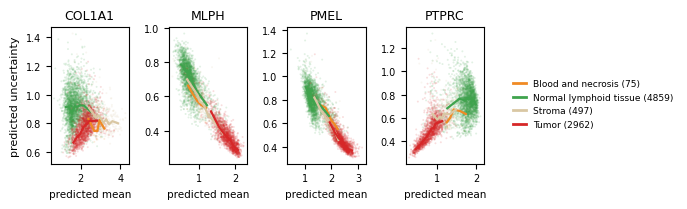


FIGURE DATA, Tumor Profiler, slide MAHEFOG-1-2: the binned medians drawn as lines.

  COL1A1
    Blood and necrosis       n=   43  mu [2.393 2.68  2.84  2.952 3.194]
                                      sigma [0.831 0.748 0.747 0.822 0.764]
    Normal lymphoid tissue   n= 2777  mu [1.24  1.382 1.472 1.544 1.615 1.703 1.807 1.944 2.153 2.504]
                                      sigma [0.913 0.917 0.89  0.876 0.892 0.919 0.914 0.925 0.923 0.882]
    Stroma                   n=  284  mu [2.421 2.626 2.77  2.879 3.032 3.147 3.291 3.439 3.604 3.892]
                                      sigma [0.907 0.868 0.839 0.855 0.832 0.805 0.827 0.793 0.815 0.8  ]
    Tumor                    n= 1693  mu [1.624 1.823 1.956 2.071 2.156 2.249 2.334 2.434 2.556 2.824]
                                      sigma [0.666 0.708 0.723 0.756 0.777 0.79  0.798 0.818 0.817 0.819]

  MLPH
    Blood and necrosis       n=   43  mu [0.692 0.812 0.948 1.06  1.191]
                                      sigma [0.66

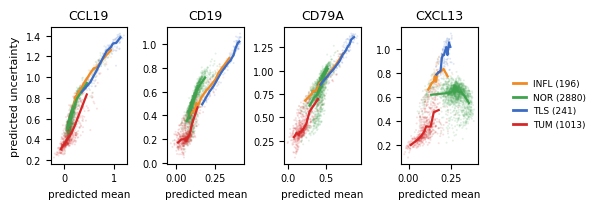


FIGURE DATA, Kidney/Lung TLS, slide LC1: the binned medians drawn as lines.

  CCL19
    INFL                     n=  112  mu [0.194 0.222 0.274 0.342 0.396 0.499 0.588 0.652 0.785 0.937]
                                      sigma [0.714 0.806 0.841 0.894 0.942 1.021 1.084 1.095 1.18  1.262]
    NOR                      n= 1646  mu [0.062 0.089 0.104 0.12  0.135 0.153 0.175 0.203 0.243 0.454]
                                      sigma [0.501 0.531 0.558 0.592 0.622 0.651 0.68  0.721 0.782 0.944]
    TLS                      n=  138  mu [0.348 0.518 0.651 0.747 0.848 0.932 0.979 1.043 1.086 1.126]
                                      sigma [0.854 0.948 1.065 1.16  1.251 1.288 1.326 1.331 1.359 1.384]
    TUM                      n=  579  mu [-0.066 -0.021  0.012  0.039  0.069  0.104  0.144  0.213  0.271  0.452]
                                      sigma [0.303 0.344 0.356 0.38  0.411 0.427 0.459 0.534 0.607 0.833]

  CD19
    INFL                     n=  112  mu [0.084 0.118 0.128 

In [3]:
N_BINS_LINE = 10
MIN_PER_BIN = 8
# One slide per cohort and a handful of genes. Edit SLIDE_PICK to look at another slide; the
# available ones are printed below.
SLIDE_PICK = {}
GENE_PICK = {}

for ds in DATASETS:
    key = (ds, MAIN)
    if key not in D or D[key]['examples'].empty:
        print(f'{ds}: no spot-level examples')
        continue
    ex = D[key]['examples']
    print(f'{DS_SHORT.get(ds, ds)}: genes {sorted(ex["gene"].unique())}')
    print(f'  slides {sorted(ex["slide"].unique())}')
    # default slide: the one with the most annotated spots, so the clouds are dense
    SLIDE_PICK.setdefault(ds, ex.groupby('slide').size().idxmax())
    GENE_PICK.setdefault(ds, sorted(ex['gene'].unique())[:4])
    print(f'  using slide {SLIDE_PICK[ds]} and genes {GENE_PICK[ds]}')


def binned_median(x, y, n_bins=N_BINS_LINE, min_n=MIN_PER_BIN):
    '''Median of y inside equal-count bins of x. Returns the bin centers and the medians.'''
    if len(x) < n_bins * min_n:
        n_bins = max(2, len(x) // min_n)
    q = np.quantile(x, np.linspace(0, 1, n_bins + 1))
    q[-1] += 1e-12
    idx = np.clip(np.searchsorted(q, x, side='right') - 1, 0, n_bins - 1)
    cx, cy = [], []
    for b in range(n_bins):
        m = idx == b
        if m.sum() >= min_n:
            cx.append(np.median(x[m]))
            cy.append(np.median(y[m]))
    return np.array(cx), np.array(cy)


from matplotlib.lines import Line2D

for ds in DATASETS:
    key = (ds, MAIN)
    if key not in D or D[key]['examples'].empty:
        continue
    ex = D[key]['examples']
    sl = SLIDE_PICK[ds]
    gl = [g for g in GENE_PICK[ds] if ((ex['slide'] == sl) & (ex['gene'] == g)).any()]
    if not gl:
        continue
    counts = ex[ex['slide'] == sl].groupby('tissue', observed=True).size() // max(len(gl), 1)
    # The legend sits OUTSIDE, on the right, and is shared by the panels: inside it would cover
    # the clouds, which are the whole content, and the tissue types are the same in every panel.
    fig, axes = plt.subplots(1, len(gl), figsize=(6.3, 2.2), squeeze=False)
    for ax, g in zip(axes[0], gl):
        sub = ex[(ex['slide'] == sl) & (ex['gene'] == g)]
        for tis, s in sub.groupby('tissue', observed=True):
            c = TISSUE_COLORS.get(tis, 'gray')
            ax.scatter(s['mu'], s['sigma'], s=2.0, alpha=0.15, edgecolors='none', color=c)
            cx, cy = binned_median(s['mu'].to_numpy(), s['sigma'].to_numpy())
            if len(cx):
                ax.plot(cx, cy, color=c, lw=1.6)
        ax.set_xlabel('predicted mean', fontsize=7.5)
        ax.tick_params(labelsize=7)
        ax.set_title(g, fontsize=9)
    axes[0][0].set_ylabel('predicted uncertainty', fontsize=8)
    order = sorted(ex[ex['slide'] == sl]['tissue'].unique())
    handles = [Line2D([0], [0], color=TISSUE_COLORS.get(t, 'gray'), lw=2.0,
                      label=f'{t} ({int(counts.get(t, 0))})') for t in order]
    fig.tight_layout(rect=[0, 0, 0.80, 1])
    fig.legend(handles=handles, loc='center left', bbox_to_anchor=(0.81, 0.5),
               frameon=False, fontsize=6.5, handlelength=1.4)
    save_fig(fig, f'tissue_matched_scatter_{ds}_{sl}')
    plt.show()

    print(f'\nFIGURE DATA, {DS_SHORT.get(ds, ds)}, slide {sl}: the binned medians drawn as lines.')
    for g in gl:
        sub = ex[(ex['slide'] == sl) & (ex['gene'] == g)]
        print(f'\n  {g}')
        for tis, s in sub.groupby('tissue', observed=True):
            cx, cy = binned_median(s['mu'].to_numpy(), s['sigma'].to_numpy())
            print(f'    {tis:24s} n={len(s):>5d}  mu {np.round(cx, 3)}')
            print(f'    {"":24s}          sigma {np.round(cy, 3)}')
    print('\nCAPTION: Predicted uncertainty against predicted mean, one point per spot, on a single'
          ' slide and for one gene per panel, colored by expert tissue type. Thick lines are the'
          ' median uncertainty inside ten equal-count bins of the predicted mean. A vertical'
          ' separation between two lines at the same horizontal position is a difference in'
          ' uncertainty that the predicted mean does not account for. Spot counts per tissue type'
          ' are given in the legend.')

## 3. The matched contrast

`mean_dsigma` is already a difference against the reference tissue type, the tumor, taken inside
pairs matched on the predicted mean. It is averaged over the (gene, slide) cells of a donor, which
gives one value per (donor, tissue type), and the donors are the unit of replication.

The same quantity is reported for the absolute error, on the very same pairs, so the question of
whether the error follows is answered on one population and not two.

In [4]:
rows = []
for (ds, model), d in D.items():
    for lab in d['summary']['label_cols']:
        t = d['matched'][d['matched']['label_col'] == lab]
        if t.empty:
            continue
        p = (t.groupby(['test_donor', 'tissue'], observed=True)[['mean_dsigma', 'mean_derr',
                                                                 'mean_abs_dmu', 'match_rate']]
              .mean().reset_index())
        p['dataset'] = ds
        p['model'] = MODEL_LABELS.get(model, model)
        p['labels'] = 'genuine' if lab == 'ground_truth' else 'imputed'
        rows.append(p)
MC = pd.concat(rows, ignore_index=True)

print('Matched difference against the tumor, per (donor, tissue type), averaged over genes and slides.')
print(MC[MC['labels'] == 'genuine']
        .groupby(['dataset', 'model', 'tissue'])[['mean_dsigma', 'mean_derr', 'mean_abs_dmu']]
        .agg(['mean', 'std', 'size']).round(5).to_string())

print('\n\nSIGN TEST over donors, immune tissue types minus tumor, on the matched pairs.\n')
out = []
for (ds, model, labels), sub in MC.groupby(['dataset', 'model', 'labels']):
    for field in ('mean_dsigma', 'mean_derr'):
        piv = sub.pivot_table(index='test_donor', columns='tissue', values=field)
        im = [c for c in piv.columns if c in IMMUNE]
        if not im:
            continue
        delta = piv[im].mean(axis=1).dropna()
        if len(delta) < 3:
            continue
        k = int((delta > 0).sum())
        ci = stats.t.interval(0.95, len(delta) - 1, loc=delta.mean(), scale=stats.sem(delta))
        out.append(dict(dataset=ds, model=model, labels=labels,
                        quantity='uncertainty' if field == 'mean_dsigma' else 'error',
                        n_donors=len(delta), mean_delta=delta.mean(),
                        ci_low=ci[0], ci_high=ci[1], positive=f'{k}/{len(delta)}',
                        sign_p=signtest_p(k, len(delta))))
MC_TEST = pd.DataFrame(out)
print(MC_TEST.round(5).to_string(index=False) if not MC_TEST.empty else '  nothing computable')
if not MC_TEST.empty:
    n_min = int(MC_TEST['n_donors'].min())
    print(f'\nSign-test floor at n = {n_min} donors: p cannot fall below {2 * 0.5 ** n_min:.3f}.')

Matched difference against the tumor, per (donor, tissue type), averaged over genes and slides.
                                        mean_dsigma               mean_derr               mean_abs_dmu              
                                               mean      std size      mean      std size         mean      std size
dataset   model  tissue                                                                                             
10x_TuPro G Gene Blood and necrosis         0.00000  0.00000    7   0.02286  0.02375    7      0.00057  0.00038    7
                 Normal lymphoid tissue     0.00000  0.00000    7   0.03309  0.03438    7      0.00125  0.00043    7
                 Stroma                     0.00000  0.00000    7   0.02108  0.02337    7      0.00108  0.00032    7
          G Het  Blood and necrosis         0.02989  0.03195    7   0.02093  0.02173    7      0.00061  0.00050    7
                 Normal lymphoid tissue     0.05973  0.03379    7   0.03241  0.03386 

/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy

wrote: fig_tissue_matched_contrast_pr_classic3.pdf


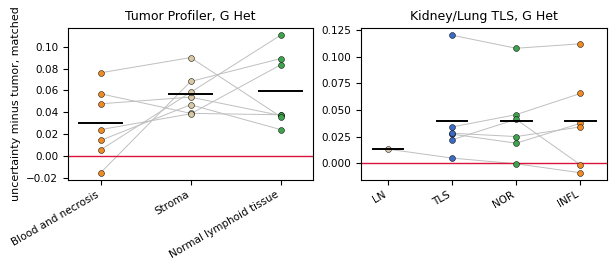


FIGURE DATA: one row per (donor, tissue type).
  dataset test_donor                 tissue  mean_dsigma  mean_derr  mean_abs_dmu  match_rate
10x_TuPro    MACEGEJ     Blood and necrosis      0.01417    0.01993       0.00036     0.98920
10x_TuPro    MAHEFOG     Blood and necrosis      0.05695    0.05718       0.00103     0.92525
10x_TuPro    MAJOFIJ     Blood and necrosis      0.04775   -0.00444       0.00056     0.95103
10x_TuPro    MAKYGIW     Blood and necrosis     -0.01545    0.02360       0.00020     0.97288
10x_TuPro    MANOFYB     Blood and necrosis      0.07618    0.03995       0.00152     0.87840
10x_TuPro    MELIPIT     Blood and necrosis      0.00553    0.00726       0.00011     0.99263
10x_TuPro    MIDEKOG     Blood and necrosis      0.02408    0.00305       0.00047     0.98374
10x_TuPro    MACEGEJ Normal lymphoid tissue      0.02412   -0.00452       0.00108     0.94516
10x_TuPro    MAHEFOG Normal lymphoid tissue      0.03767    0.05226       0.00199     0.86852
10x_TuPro   

In [5]:
# One panel per cohort, the main model, genuine labels. Zero is the reference tissue type, so a
# point above zero is a tissue type whose uncertainty exceeds the tumor AT THE SAME PREDICTED MEAN.
sub_all = MC[(MC['model'] == MODEL_LABELS[MAIN]) & (MC['labels'] == 'genuine')]
dss = [ds for ds in DATASETS if (sub_all['dataset'] == ds).any()]
if dss:
    fig, axes = plt.subplots(1, len(dss), figsize=(6.3, 2.8), squeeze=False)
    for ax, ds in zip(axes[0], dss):
        sub = sub_all[sub_all['dataset'] == ds]
        order = sub.groupby('tissue')['mean_dsigma'].mean().sort_values().index.tolist()
        piv = sub.pivot_table(index='test_donor', columns='tissue', values='mean_dsigma').reindex(columns=order)
        x = np.arange(len(order))
        for _, r in piv.iterrows():
            ax.plot(x, r.to_numpy(), color='0.75', lw=0.7, zorder=1)
        for i, tis in enumerate(order):
            v = piv[tis].dropna()
            ax.scatter(np.full(len(v), i), v, s=18, color=TISSUE_COLORS.get(tis, 'gray'),
                       edgecolors='k', linewidths=0.35, zorder=3)
            ax.plot([i - 0.24, i + 0.24], [v.mean()] * 2, color='k', lw=1.4, zorder=4)
        ax.axhline(0, color='crimson', lw=1.0, zorder=2)
        ax.set_xticks(x)
        ax.set_xticklabels(order, rotation=30, ha='right', fontsize=7)
        ax.tick_params(labelsize=7.5)
        ax.set_title(f'{DS_SHORT.get(ds, ds)}, {MODEL_LABELS[MAIN]}', fontsize=9)
    axes[0][0].set_ylabel('uncertainty minus tumor, matched', fontsize=8)
    fig.tight_layout()
    save_fig(fig, 'tissue_matched_contrast')
    plt.show()
    print('\nFIGURE DATA: one row per (donor, tissue type).')
    print(sub_all.sort_values(['dataset', 'tissue', 'test_donor'])
                 [['dataset', 'test_donor', 'tissue', 'mean_dsigma', 'mean_derr', 'mean_abs_dmu',
                   'match_rate']].round(5).to_string(index=False))
    print('\nCAPTION: Difference in predicted uncertainty between each tissue type and the tumor,'
          ' taken inside pairs of spots matched on the predicted mean within a gene and a slide,'
          ' then averaged over genes and slides. One point per held-out donor, a gray line joining'
          ' the tissue types of one donor, the black rule the donor mean and the red line the'
          ' tumor reference. Genuine expert labels only.')

wrote: fig_tissue_matched_distribution_pr_classic3.pdf


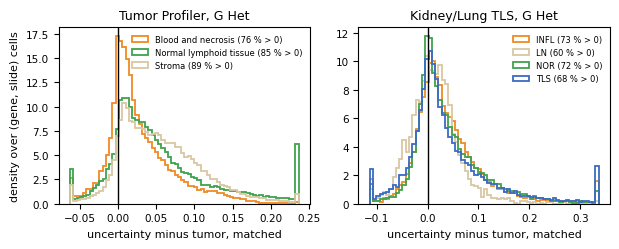


FIGURE DATA: the distribution of the matched difference over (gene, slide) cells.
  dataset                 tissue  n_cells  frac_above_zero     p10  median    p90   mean
10x_TuPro     Blood and necrosis    47980           0.7571 -0.0139  0.0163 0.0880 0.0273
10x_TuPro Normal lymphoid tissue    54000           0.8478 -0.0089  0.0365 0.1460 0.0533
10x_TuPro                 Stroma    53991           0.8918 -0.0011  0.0473 0.1263 0.0551
      TLS                   INFL    17997           0.7336 -0.0250  0.0248 0.1219 0.0398
      TLS                     LN     2932           0.6037 -0.0448  0.0111 0.0685 0.0132
      TLS                    NOR    18000           0.7186 -0.0224  0.0224 0.1297 0.0397
      TLS                    TLS    17832           0.6812 -0.0367  0.0177 0.1392 0.0392

frac_above_zero is the readable number: the share of (gene, slide) cells in which the
non-tumor spot is the more uncertain of the matched pair. A mean can be carried by a tail;
a fraction near 0.5 would s

In [6]:
# ===== The distribution of the matched difference, one curve per tissue type =====
# The contrast above is a mean of means. This shows what that mean is made of: the matched
# difference of every (gene, slide) cell. The number that matters is the fraction of cells above
# zero, printed below, because a mean can be carried by a tail whereas a fraction cannot.
#
# The horizontal range is clipped to the 1st and 99th percentiles of the pooled values so the
# curves are readable; the printed quantiles are computed on the unclipped values.
sub_all = D
dss = [ds for ds in DATASETS if (ds, MAIN) in D]
fig, axes = plt.subplots(1, len(dss), figsize=(6.3, 2.6), squeeze=False)
for ax, ds in zip(axes[0], dss):
    t = D[(ds, MAIN)]['matched']
    t = t[t['label_col'] == LABEL_PRIMARY]
    lo, hi = np.percentile(t['mean_dsigma'], [1, 99])
    for tis, s in t.groupby('tissue', observed=True):
        v = s['mean_dsigma'].to_numpy()
        v = v[np.isfinite(v)]
        ax.hist(np.clip(v, lo, hi), bins=70, range=(lo, hi), density=True, histtype='step',
                lw=1.3, color=TISSUE_COLORS.get(tis, 'gray'),
                label=f'{tis} ({100 * (v > 0).mean():.0f} % > 0)')
    ax.axvline(0, color='k', lw=1.0)
    ax.set_xlabel('uncertainty minus tumor, matched', fontsize=8)
    ax.tick_params(labelsize=7.5)
    ax.set_title(f'{DS_SHORT.get(ds, ds)}, {MODEL_LABELS[MAIN]}', fontsize=9)
    ax.legend(fontsize=6, frameon=False)
axes[0][0].set_ylabel('density over (gene, slide) cells', fontsize=8)
fig.tight_layout()
save_fig(fig, 'tissue_matched_distribution')
plt.show()

print('\nFIGURE DATA: the distribution of the matched difference over (gene, slide) cells.')
rows = []
for ds in dss:
    t = D[(ds, MAIN)]['matched']
    t = t[t['label_col'] == LABEL_PRIMARY]
    for tis, s in t.groupby('tissue', observed=True):
        v = s['mean_dsigma'].to_numpy()
        rows.append(dict(dataset=ds, tissue=tis, n_cells=len(v),
                         frac_above_zero=float((v > 0).mean()),
                         p10=float(np.percentile(v, 10)), median=float(np.median(v)),
                         p90=float(np.percentile(v, 90)), mean=float(v.mean())))
DIST = pd.DataFrame(rows)
print(DIST.round(4).to_string(index=False))
print('\nfrac_above_zero is the readable number: the share of (gene, slide) cells in which the')
print('non-tumor spot is the more uncertain of the matched pair. A mean can be carried by a tail;')
print('a fraction near 0.5 would say the effect is a tail even if the mean is positive.')
print('\nCAPTION: Distribution of the difference in predicted uncertainty between each tissue type'
      ' and the tumor, taken inside pairs of spots matched on the predicted mean, one value per'
      ' gene and slide. The vertical line marks equality. The share of values above it is given in'
      ' the legend. Values are clipped to the first and ninety-ninth percentiles for display.')

## 4. The same question through a linear model

Inside each (gene, slide) the uncertainty is regressed on the predicted mean, linearly, and the
tissue means of the residual are taken. That is the textbook control, and it assumes a straight
line where the matching assumes nothing about the shape.

Agreement between the two is worth more than either alone. Disagreement means the relation between
the uncertainty and the predicted mean is not linear inside a gene, and then the matching is the
one to trust.

In [7]:
rows = []
for (ds, model), d in D.items():
    a = d['ancova']
    if a.empty:
        continue
    a = a[a['label_col'] == LABEL_PRIMARY]
    if a.empty:
        continue
    p = (a.groupby(['test_donor', 'tissue'], observed=True)[['resid_sigma', 'resid_err', 'slope']]
          .mean().reset_index())
    p['dataset'] = ds
    p['model'] = MODEL_LABELS.get(model, model)
    rows.append(p)
AN = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

if not AN.empty:
    print('Mean residual uncertainty per (donor, tissue type), after regressing out the predicted mean.')
    print(AN.groupby(['dataset', 'model', 'tissue'])[['resid_sigma', 'resid_err', 'slope']]
            .agg(['mean', 'std']).round(5).to_string())
    print('\nslope is the coefficient of the predicted mean inside a (gene, slide). Its sign says')
    print('which way the uncertainty moves with the mean WITHIN a gene, which is not the direction')
    print('it moves BETWEEN genes.\n')

    # The contrast, built exactly like the matched one so the two are comparable line by line.
    out = []
    for (ds, model), sub in AN.groupby(['dataset', 'model']):
        piv = sub.pivot_table(index='test_donor', columns='tissue', values='resid_sigma')
        im = [c for c in piv.columns if c in IMMUNE]
        tu = [c for c in piv.columns if c in {'Tumor', 'TUM'}]
        if not im or not tu:
            continue
        delta = (piv[im].mean(axis=1) - piv[tu].mean(axis=1)).dropna()
        if len(delta) < 3:
            continue
        k = int((delta > 0).sum())
        ci = stats.t.interval(0.95, len(delta) - 1, loc=delta.mean(), scale=stats.sem(delta))
        out.append(dict(dataset=ds, model=model, method='linear model', n_donors=len(delta),
                        mean_delta=delta.mean(), ci_low=ci[0], ci_high=ci[1],
                        positive=f'{k}/{len(delta)}', sign_p=signtest_p(k, len(delta))))
    LM_TEST = pd.DataFrame(out)

    print('THE TWO METHODS SIDE BY SIDE, immune tissue types minus tumor.\n')
    both = pd.concat([
        MC_TEST[MC_TEST['quantity'] == 'uncertainty'].assign(method='matching')
               [['dataset', 'model', 'method', 'n_donors', 'mean_delta', 'ci_low', 'ci_high',
                 'positive', 'sign_p']],
        LM_TEST], ignore_index=True) if not LM_TEST.empty else MC_TEST
    print(both.sort_values(['dataset', 'model', 'method']).round(5).to_string(index=False))
    print('\nSame sign and overlapping intervals means the answer does not depend on how the mean')
    print('was held fixed. A disagreement points at the shape of the relation, not at the biology.')

Mean residual uncertainty per (donor, tissue type), after regressing out the predicted mean.
                                        resid_sigma          resid_err              slope         
                                               mean      std      mean      std      mean      std
dataset   model  tissue                                                                           
10x_TuPro G Gene Blood and necrosis        -0.00000  0.00000   0.01360  0.01505  -0.00000  0.00000
                 Normal lymphoid tissue    -0.00000  0.00000   0.02226  0.03058  -0.00000  0.00000
                 Stroma                    -0.00000  0.00000   0.00947  0.02318  -0.00000  0.00000
                 Tumor                     -0.00000  0.00000  -0.00724  0.01115  -0.00000  0.00000
          G Het  Blood and necrosis         0.01275  0.02431   0.01177  0.01325   0.39906  0.08095
                 Normal lymphoid tissue     0.03770  0.03504   0.02158  0.03078   0.39752  0.07641
                

/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


## 5. The report figure

One block, three rows, one column per cohort. It carries the whole argument in the order it has to
be read.

- **(a)** the control made visible: uncertainty against predicted mean, one gene on one slide,
  colored by tissue type. A vertical gap between two lines at the same horizontal position is a
  difference the predicted mean does not account for.
- **(b)** the effect: the matched difference against the tumor, one point per held-out donor.
- **(c)** its generality: the same difference over every (gene, slide) cell, with the share above
  zero.

Built as a single PDF so that the fonts and the panel sizes stay consistent and the `.tex` includes
one file. Panels are lettered and every plotted number is printed below.

wrote: fig_uncertainty_by_tissue_matched_pr_classic3.pdf


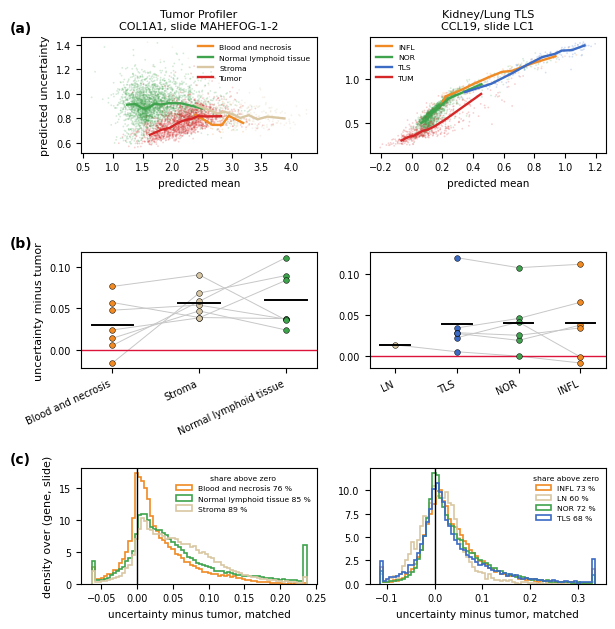


FIGURE DATA (a): the binned medians drawn as lines.

  Tumor Profiler, gene COL1A1, slide MAHEFOG-1-2
    Blood and necrosis       n=   43  mu    [2.393 2.68  2.84  2.952 3.194]
                                      sigma [0.831 0.748 0.747 0.822 0.764]
    Normal lymphoid tissue   n= 2777  mu    [1.24  1.382 1.472 1.544 1.615 1.703 1.807 1.944 2.153 2.504]
                                      sigma [0.913 0.917 0.89  0.876 0.892 0.919 0.914 0.925 0.923 0.882]
    Stroma                   n=  284  mu    [2.421 2.626 2.77  2.879 3.032 3.147 3.291 3.439 3.604 3.892]
                                      sigma [0.907 0.868 0.839 0.855 0.832 0.805 0.827 0.793 0.815 0.8  ]
    Tumor                    n= 1693  mu    [1.624 1.823 1.956 2.071 2.156 2.249 2.334 2.434 2.556 2.824]
                                      sigma [0.666 0.708 0.723 0.756 0.777 0.79  0.798 0.818 0.817 0.819]

  Kidney/Lung TLS, gene CCL19, slide LC1
    INFL                     n=  112  mu    [0.194 0.222 0.274 0.34

In [8]:
# ===== THE PAPER FIGURE: one block, three rows, one column per cohort =====
# Row (a) the control, row (b) the effect, row (c) its generality. Sized for a portrait page at
# roughly its printed width, so the fonts are not shrunk by \includegraphics[width=\textwidth].
# No suptitle: the title belongs in the LaTeX caption.
COHORTS = [ds for ds in DATASETS if (ds, MAIN) in D]
PANEL_GENE = {ds: GENE_PICK[ds][0] for ds in COHORTS if ds in GENE_PICK}   # edit to pick another

fig, axes = plt.subplots(3, len(COHORTS), figsize=(6.3, 6.4), squeeze=False)

for j, ds in enumerate(COHORTS):
    t = D[(ds, MAIN)]['matched']
    t = t[t['label_col'] == LABEL_PRIMARY]
    ex = D[(ds, MAIN)]['examples']
    sl, g = SLIDE_PICK[ds], PANEL_GENE[ds]

    # ---- (a) the control: uncertainty against predicted mean, one gene, one slide ----
    ax = axes[0, j]
    sub = ex[(ex['slide'] == sl) & (ex['gene'] == g)]
    for tis, s in sub.groupby('tissue', observed=True):
        c = TISSUE_COLORS.get(tis, 'gray')
        ax.scatter(s['mu'], s['sigma'], s=1.6, alpha=0.22, edgecolors='none', color=c)
        cx, cy = binned_median(s['mu'].to_numpy(), s['sigma'].to_numpy())
        if len(cx):
            ax.plot(cx, cy, color=c, lw=1.7, label=tis)
    ax.set_xlabel('predicted mean', fontsize=7.5)
    ax.legend(fontsize=5.5, frameon=False, loc='best')
    ax.set_title(f'{DS_SHORT.get(ds, ds)}\n{g}, slide {sl}', fontsize=8)

    # ---- (b) the effect: matched difference against the tumor, one point per donor ----
    ax = axes[1, j]
    mc = MC[(MC['dataset'] == ds) & (MC['model'] == MODEL_LABELS[MAIN]) & (MC['labels'] == 'genuine')]
    order = mc.groupby('tissue')['mean_dsigma'].mean().sort_values().index.tolist()
    piv = mc.pivot_table(index='test_donor', columns='tissue', values='mean_dsigma').reindex(columns=order)
    x = np.arange(len(order))
    for _, r in piv.iterrows():
        ax.plot(x, r.to_numpy(), color='0.78', lw=0.7, zorder=1)
    for i, tis in enumerate(order):
        v = piv[tis].dropna()
        ax.scatter(np.full(len(v), i), v, s=17, color=TISSUE_COLORS.get(tis, 'gray'),
                   edgecolors='k', linewidths=0.35, zorder=3)
        ax.plot([i - 0.24, i + 0.24], [v.mean()] * 2, color='k', lw=1.4, zorder=4)
    ax.axhline(0, color='crimson', lw=1.0, zorder=2)
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=25, ha='right', fontsize=6.5)

    # ---- (c) its generality: the distribution over (gene, slide) cells ----
    ax = axes[2, j]
    lo, hi = np.percentile(t['mean_dsigma'], [1, 99])
    for tis, s in t.groupby('tissue', observed=True):
        v = s['mean_dsigma'].to_numpy()
        v = v[np.isfinite(v)]
        ax.hist(np.clip(v, lo, hi), bins=70, range=(lo, hi), density=True, histtype='step',
                lw=1.2, color=TISSUE_COLORS.get(tis, 'gray'),
                label=f'{tis} {100 * (v > 0).mean():.0f} %')
    ax.axvline(0, color='k', lw=1.0)
    ax.set_xlabel('uncertainty minus tumor, matched', fontsize=7.5)
    ax.legend(fontsize=5.5, frameon=False, title='share above zero', title_fontsize=5.5)

for r in range(3):
    for c in range(len(COHORTS)):
        axes[r, c].tick_params(labelsize=7)
axes[0, 0].set_ylabel('predicted uncertainty', fontsize=8)
axes[1, 0].set_ylabel('uncertainty minus tumor', fontsize=8)
axes[2, 0].set_ylabel('density over (gene, slide)', fontsize=8)
for r, lab in enumerate('abc'):
    axes[r, 0].annotate(f'({lab})', xy=(-0.30, 1.02), xycoords='axes fraction',
                        fontsize=10, fontweight='bold', va='bottom')
fig.tight_layout()
save_fig(fig, 'uncertainty_by_tissue_matched')
plt.show()

# ---- the printed twin, panel by panel ----
print('\nFIGURE DATA (a): the binned medians drawn as lines.')
for ds in COHORTS:
    ex = D[(ds, MAIN)]['examples']
    sl, g = SLIDE_PICK[ds], PANEL_GENE[ds]
    print(f'\n  {DS_SHORT.get(ds, ds)}, gene {g}, slide {sl}')
    for tis, s in ex[(ex['slide'] == sl) & (ex['gene'] == g)].groupby('tissue', observed=True):
        cx, cy = binned_median(s['mu'].to_numpy(), s['sigma'].to_numpy())
        print(f'    {tis:24s} n={len(s):>5d}  mu    {np.round(cx, 3)}')
        print(f'    {"":24s}          sigma {np.round(cy, 3)}')

print('\nFIGURE DATA (b): one row per (donor, tissue type).')
print(MC[(MC['model'] == MODEL_LABELS[MAIN]) & (MC['labels'] == 'genuine')]
        .sort_values(['dataset', 'tissue', 'test_donor'])
        [['dataset', 'test_donor', 'tissue', 'mean_dsigma', 'mean_derr', 'mean_abs_dmu',
          'match_rate']].round(5).to_string(index=False))

print('\nFIGURE DATA (c): the distribution over (gene, slide) cells.')
print(DIST.round(4).to_string(index=False))

print('\nCAPTION: Predicted uncertainty by tissue type, at the same predicted mean. Columns are the'
      ' two cohorts that carry a per-spot expert annotation. (a) Uncertainty against predicted mean'
      ' for one gene on one slide, one point per spot, colored by tissue type, with the median'
      ' uncertainty inside ten equal-count bins of the predicted mean drawn as a line; a vertical'
      ' gap at the same horizontal position is a difference the predicted mean does not account'
      ' for. (b) Difference in uncertainty between each tissue type and the tumor, taken inside'
      ' pairs of spots matched on the predicted mean within a gene and a slide, one point per'
      ' held-out donor, a gray line joining the tissue types of one donor, the black rule the donor'
      ' mean and the red line the tumor reference. (c) The same difference over every (gene,'
      ' slide) cell, the vertical line marking equality and the legend giving the share above it.')

In [9]:
# ===== INGREDIENTS for the full page figure =====
# Three sources are needed beyond what this notebook already holds: the variance shares of the
# tissue_sigma precompute, the cohort composition from the merged adata, and a two-dimensional
# embedding of the spot representations.
import anndata as ad

QNAMES = {'log_mu': 'expression', 'log_sigma': 'uncertainty',
          'log_alpha': 'NB dispersion', 'log_abs_err': 'error'}
QORDER = ['expression', 'uncertainty', 'NB dispersion', 'error']
QCOL = {'expression': '#1f77b4', 'uncertainty': '#B2182B',
        'NB dispersion': '#9467bd', 'error': '#333333'}
SHARE_DATASETS = ['10x_TuPro', 'TLS', 'LUNG_CANCER']
COHORT_TAG = {'10x_TuPro': 'T', 'TLS': 'K', 'LUNG_CANCER': 'N'}
NBK = 'negativebinomial_hetero_noanchor_cp'
DROP = {'PIGMENT', 'UNASSIGNED', 'NAN', 'NONE', 'NA', 'N/A', '', '<NA>', 'MIXED', 'WHITESPACE'}

# ---- A: the variance shares, from the OTHER precompute ----
rows = []
for ds in SHARE_DATASETS:
    for model in (MAIN, NBK):
        f = leaf(ds, model) / 'tissue_sigma' / 'shares.parquet'
        if not f.exists():
            print(f'MISSING shares  {ds:12s} {MODEL_LABELS.get(model, model)}')
            continue
        s = pd.read_parquet(f)
        s['dataset'] = ds
        s['model'] = MODEL_LABELS.get(model, model)
        rows.append(s)
SH = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
if not SH.empty:
    SH['quantity'] = SH['quantity'].map(lambda q: QNAMES.get(q, q))
    print('shares loaded:', sorted(SH['dataset'].unique()), '|', sorted(SH['quantity'].unique()))
    if 'expression' not in set(SH['quantity']):
        print('  NOTE: no expression arm. Re-run the tissue_sigma precompute with FORCE=1.')

# ---- E and F: the cohort composition and the embedding ----
if 'UMAP_CACHE' not in dir():
    UMAP_CACHE = {}
LABEL_COUNTS = {}
N_SUB, SEED, EMB_KEY = 20000, 0, 'X_emb'

for ds in DATASETS:
    key = (ds, MAIN)
    if key not in D:
        continue
    path = D[key]['summary']['input_adata']
    A = ad.read_h5ad(path, backed='r')
    LABEL_COUNTS[ds] = A.obs['ground_truth'].astype(str).value_counts()
    A.file.close()
    del A
    print(f'{ds:12s} composition: {dict(LABEL_COUNTS[ds])}')

    if ds in UMAP_CACHE:
        print(f'  embedding: cached ({UMAP_CACHE[ds][1]})')
        continue
    import scanpy as sc
    A = ad.read_h5ad(path)
    if EMB_KEY not in A.obsm:
        print(f'  no obsm[{EMB_KEY!r}], skipped')
        del A
        continue
    lab = A.obs['ground_truth'].to_numpy().astype(str)
    keep = np.flatnonzero(~np.isin(np.char.upper(lab), list(DROP)))
    if len(keep) > N_SUB:
        keep = np.sort(np.random.default_rng(SEED).choice(keep, N_SUB, replace=False))
    Xe = np.asarray(A.obsm[EMB_KEY])[keep].astype(np.float32)
    lab = lab[keep]
    del A
    sub = ad.AnnData(X=Xe)
    sc.pp.pca(sub, n_comps=50)
    method = 'PC1 / PC2'
    try:
        sc.pp.neighbors(sub, n_neighbors=15, use_rep='X_pca')
        sc.tl.umap(sub, random_state=SEED)
        Y, method = sub.obsm['X_umap'], 'UMAP1 / UMAP2'
    except Exception as e:
        print(f'  UMAP unavailable ({type(e).__name__}), falling back to two principal components')
        Y = sub.obsm['X_pca'][:, :2]
    UMAP_CACHE[ds] = (Y, method, lab)
    print(f'  embedding: {len(keep):,} spots, {method}')

print('\ningredients ready:',
      f'shares {SH.shape}', f'| composition {list(LABEL_COUNTS)}', f'| embedding {list(UMAP_CACHE)}')

shares loaded: ['10x_TuPro', 'LUNG_CANCER', 'TLS'] | ['NB dispersion', 'error', 'expression', 'uncertainty']
10x_TuPro    composition: {'Tumor': np.int64(52240), 'Normal lymphoid tissue': np.int64(12938), 'Stroma': np.int64(9969), 'Blood and necrosis': np.int64(2173), 'Pigment': np.int64(18)}
  embedding: 20,000 spots, UMAP1 / UMAP2
TLS          composition: {'UNASSIGNED': np.int64(10110), 'NOR': np.int64(4410), 'TUM': np.int64(3705), 'TLS': np.int64(775), 'INFL': np.int64(404), 'LN': np.int64(33)}
  embedding: 9,327 spots, UMAP1 / UMAP2

ingredients ready: shares (147, 11) | composition ['10x_TuPro', 'TLS'] | embedding ['10x_TuPro', 'TLS']


wrote: fig_uncertainty_by_tissue_full_pr_classic3.pdf


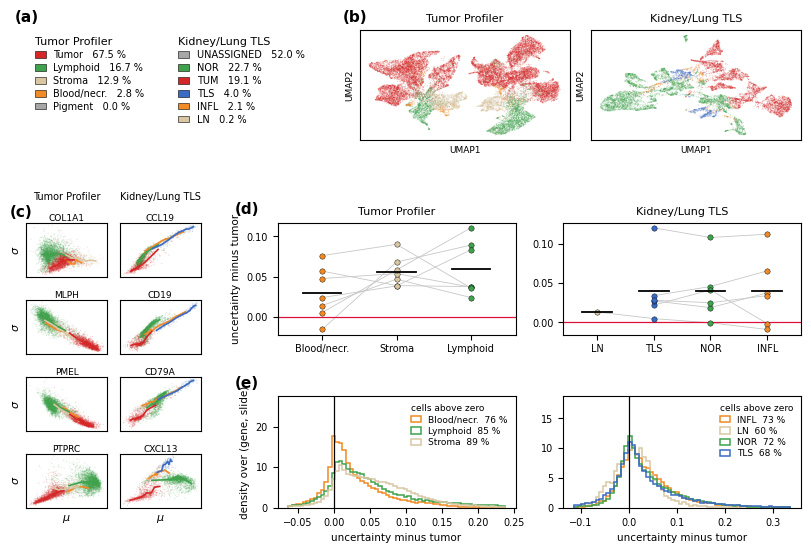


FIGURE DATA (a): cohort composition, the percentages printed in the legend.
  Tumor Profiler
                            n  percent
ground_truth                          
Tumor                   52240    67.55
Normal lymphoid tissue  12938    16.73
Stroma                   9969    12.89
Blood and necrosis       2173     2.81
Pigment                    18     0.02
  Kidney/Lung TLS
                  n  percent
ground_truth                
UNASSIGNED    10110    52.01
NOR            4410    22.69
TUM            3705    19.06
TLS             775     3.99
INFL            404     2.08
LN               33     0.17

FIGURE DATA (b): spots drawn per cohort.
  Tumor Profiler: 20,000 spots, UMAP1 / UMAP2, {'Tumor': np.int64(13548), 'Normal lymphoid tissue': np.int64(3342), 'Stroma': np.int64(2566), 'Blood and necrosis': np.int64(544)}
  Kidney/Lung TLS: 9,327 spots, UMAP1 / UMAP2, {'NOR': np.int64(4410), 'TUM': np.int64(3705), 'TLS': np.int64(775), 'INFL': np.int64(404), 'LN': np.int64(33)}

FI

In [10]:
# ===== THE FULL PAGE FIGURE =====
#   a  legend and cohort composition, defined once     b  spot embedding
#   c  uncertainty against predicted mean, 4 markers   d  matched difference, per donor
#                                                      e  its distribution over (gene, slide)
# Tumor Profiler on the left, Kidney/Lung TLS on the right, in every block.
COHORTS = [ds for ds in DATASETS if (ds, MAIN) in D]
C_GENES = {ds: GENE_PICK[ds][:4] for ds in COHORTS if ds in GENE_PICK}
SHORT_TISSUE = {'Normal lymphoid tissue': 'Lymphoid', 'Blood and necrosis': 'Blood/necr.'}
HEAD_ROOM = 1.55
from matplotlib.patches import Patch

fig = plt.figure(figsize=(10.0, 6.2))
gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 2.6], hspace=0.42)
top = gs[0].subgridspec(1, 2, width_ratios=[1.0, 1.6], wspace=0.16)
bot = gs[1].subgridspec(1, 2, width_ratios=[1.0, 3.0], wspace=0.22)


def panel_letter(ax, letter, dx=-0.22, dy=1.05):
    ax.annotate(f'({letter})', xy=(dx, dy), xycoords='axes fraction',
                fontsize=11, fontweight='bold', va='bottom')


# ---------- a: the legend, with the composition folded in ----------
axA = fig.add_subplot(top[0])
axA.axis('off')
prev = None
for i, ds in enumerate(COHORTS):
    vc = LABEL_COUNTS[ds]
    handles = []
    for t in vc.index:
        pct = 100 * vc[t] / vc.sum()
        col = '0.65' if str(t).upper() in DROP else TISSUE_COLORS.get(t, 'gray')
        handles.append(Patch(facecolor=col, edgecolor='k', linewidth=0.4,
                             label=f'{SHORT_TISSUE.get(t, t)}   {pct:.1f} %'))
    lg = axA.legend(handles=handles, loc='upper left', frameon=False, fontsize=7,
                    title=DS_SHORT.get(ds, ds), title_fontsize=8, handlelength=1.1,
                    labelspacing=0.30, bbox_to_anchor=(0.0, 1.02) if i == 0 else (0.52, 1.02))
    lg._legend_box.align = 'left'
    if prev is not None:
        axA.add_artist(prev)
    prev = lg
panel_letter(axA, 'a', dx=-0.04)

# ---------- b: the spot embedding ----------
gsB = top[1].subgridspec(1, len(COHORTS), wspace=0.10)
for j, ds in enumerate(COHORTS):
    ax = fig.add_subplot(gsB[j])
    if ds not in UMAP_CACHE:
        ax.axis('off')
        continue
    Y, method, lab = UMAP_CACHE[ds]
    for tis in pd.unique(lab):
        m = lab == tis
        ax.scatter(Y[m, 0], Y[m, 1], s=0.6, alpha=0.30, edgecolors='none',
                   color=TISSUE_COLORS.get(tis, 'gray'))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(DS_SHORT.get(ds, ds), fontsize=8)
    # Both axes named on EVERY panel. An embedding coordinate has no unit, only a name, and a
    # reader should not have to look at the neighboring panel to learn what the axes are.
    xname, yname = (method.split(' / ') + [method, method])[:2]
    ax.set_xlabel(xname, fontsize=6.5)
    ax.set_ylabel(yname, fontsize=6.5)
    if j == 0:
        panel_letter(ax, 'b', dx=-0.08)

# ---------- c: uncertainty against predicted mean, four markers ----------
gsC = bot[0].subgridspec(len(C_GENES[COHORTS[0]]), len(COHORTS), wspace=0.16, hspace=0.42)
for j, ds in enumerate(COHORTS):
    ex = D[(ds, MAIN)]['examples']
    sl = SLIDE_PICK[ds]
    for i, g in enumerate(C_GENES[ds]):
        ax = fig.add_subplot(gsC[i, j])
        sub = ex[(ex['slide'] == sl) & (ex['gene'] == g)]
        for tis, s in sub.groupby('tissue', observed=True):
            c = TISSUE_COLORS.get(tis, 'gray')
            ax.scatter(s['mu'], s['sigma'], s=0.8, alpha=0.20, edgecolors='none', color=c)
            cx, cy = binned_median(s['mu'].to_numpy(), s['sigma'].to_numpy())
            if len(cx):
                ax.plot(cx, cy, color=c, lw=1.2)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(g, fontsize=6.5, pad=1.5)
        if i == 0 and j == 0:
            panel_letter(ax, 'c', dx=-0.20)
        if i == 0:
            ax.annotate(DS_SHORT.get(ds, ds), xy=(0.5, 1.42), xycoords='axes fraction',
                        ha='center', fontsize=7)
        # sigma on the left of every row, mu under every column, so each square is readable on its
        # own rather than by inheriting the axes of a neighbor
        if j == 0:
            ax.set_ylabel(r'$\sigma$', fontsize=8)
        if i == len(C_GENES[ds]) - 1:
            ax.set_xlabel(r'$\mu$', fontsize=8)

# ---------- d and e: the matched contrast and its distribution ----------
right = bot[1].subgridspec(2, 1, hspace=0.55)
gsD = right[0].subgridspec(1, len(COHORTS), wspace=0.20)
gsE = right[1].subgridspec(1, len(COHORTS), wspace=0.20)
outside = []
for j, ds in enumerate(COHORTS):
    # --- d ---
    ax = fig.add_subplot(gsD[j])
    mc = MC[(MC['dataset'] == ds) & (MC['model'] == MODEL_LABELS[MAIN]) & (MC['labels'] == 'genuine')]
    order = mc.groupby('tissue')['mean_dsigma'].mean().sort_values().index.tolist()
    piv = mc.pivot_table(index='test_donor', columns='tissue', values='mean_dsigma').reindex(columns=order)
    x = np.arange(len(order))
    for _, r in piv.iterrows():
        ax.plot(x, r.to_numpy(), color='0.78', lw=0.6, zorder=1)
    for i, tis in enumerate(order):
        v = piv[tis].dropna()
        ax.scatter(np.full(len(v), i), v, s=15, color=TISSUE_COLORS.get(tis, 'gray'),
                   edgecolors='k', linewidths=0.3, zorder=3)
        ax.plot([i - 0.26, i + 0.26], [v.mean()] * 2, color='k', lw=1.3, zorder=4)
    ax.axhline(0, color='crimson', lw=0.9, zorder=2)
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([SHORT_TISSUE.get(t, t) for t in order], fontsize=7)
    ax.set_title(DS_SHORT.get(ds, ds), fontsize=8)
    ax.tick_params(labelsize=7)
    if j == 0:
        ax.set_ylabel('uncertainty minus tumor', fontsize=7.5)
        panel_letter(ax, 'd', dx=-0.18)

    # --- e ---
    ax = fig.add_subplot(gsE[j])
    t = D[(ds, MAIN)]['matched']
    t = t[t['label_col'] == LABEL_PRIMARY]
    lo, hi = np.percentile(t['mean_dsigma'], [1, 99])
    ymax = 0.0
    for tis, s in t.groupby('tissue', observed=True):
        v = s['mean_dsigma'].to_numpy()
        v = v[np.isfinite(v)]
        # range= drops what falls outside instead of stacking it on the edge
        n, _, _ = ax.hist(v, bins=60, range=(lo, hi), density=True, histtype='step', lw=1.1,
                          color=TISSUE_COLORS.get(tis, 'gray'),
                          label=f'{SHORT_TISSUE.get(tis, tis)}  {100 * (v > 0).mean():.0f} %')
        ymax = max(ymax, float(np.max(n)))
        outside.append(dict(dataset=ds, tissue=tis,
                            frac_outside_drawn_range=float(((v < lo) | (v > hi)).mean())))
    ax.axvline(0, color='k', lw=0.9)
    # headroom, so the legend sits in empty space by construction and never reaches a curve
    ax.set_ylim(0, ymax * HEAD_ROOM)
    ax.set_xlabel('uncertainty minus tumor', fontsize=7.5)
    ax.tick_params(labelsize=7)
    lg = ax.legend(fontsize=6.5, frameon=False, title='cells above zero', title_fontsize=6.5,
                   loc='upper right', handlelength=1.1, labelspacing=0.25)
    lg._legend_box.align = 'left'
    if j == 0:
        ax.set_ylabel('density over (gene, slide)', fontsize=7.5)
        panel_letter(ax, 'e', dx=-0.18)

save_fig(fig, 'uncertainty_by_tissue_full')
plt.show()

# ---------- the printed twin ----------
print('\nFIGURE DATA (a): cohort composition, the percentages printed in the legend.')
for ds in COHORTS:
    vc = LABEL_COUNTS[ds]
    print(f'  {DS_SHORT.get(ds, ds)}')
    print(pd.DataFrame(dict(n=vc, percent=(100 * vc / vc.sum()).round(2))).to_string())
print('\nFIGURE DATA (b): spots drawn per cohort.')
for ds, (Y, method, lab) in UMAP_CACHE.items():
    print(f'  {DS_SHORT.get(ds, ds)}: {len(lab):,} spots, {method}, '
          f'{dict(pd.Series(lab).value_counts())}')
print('\nFIGURE DATA (c): genes and slides drawn:', C_GENES, SLIDE_PICK)
print('  the binned medians are printed in section 2.')
print('\nFIGURE DATA (d): one row per (donor, tissue type).')
print(MC[(MC['model'] == MODEL_LABELS[MAIN]) & (MC['labels'] == 'genuine')]
        .sort_values(['dataset', 'tissue', 'test_donor'])
        [['dataset', 'test_donor', 'tissue', 'mean_dsigma', 'mean_derr']].round(5).to_string(index=False))
print('\nFIGURE DATA (e): the distribution over (gene, slide) cells.')
print(DIST.round(4).to_string(index=False))
print('\n  share of values falling OUTSIDE the drawn range, therefore not shown:')
print(pd.DataFrame(outside).round(4).to_string(index=False))
print('\n  shortened tick labels:', SHORT_TISSUE)

print('\nCAPTION: How the predicted uncertainty varies with the tissue type, at the same predicted'
      ' mean. Tumor Profiler on the left of each block, Kidney/Lung TLS on the right. (a) Tissue'
      ' types of each cohort with the share of spots they represent, gray marking the categories'
      ' excluded from the analysis. (b) Two-dimensional embedding of the frozen histology patch'
      ' representations, colored by tissue type, on a random subsample of the annotated spots.'
      ' (c) Predicted uncertainty against predicted mean on one slide, one point per spot, one gene'
      ' per square, with the median inside ten equal-count bins of the predicted mean drawn as a'
      ' line; a vertical gap between two lines at the same horizontal position is a difference the'
      ' predicted mean does not account for. (d) Difference in uncertainty between each tissue type'
      ' and the tumor, taken inside pairs of spots matched on the predicted mean within a gene and'
      ' a slide, one point per held-out donor, a gray line joining the tissue types of one donor,'
      ' the black rule the donor mean and the red line the tumor reference. (e) The same'
      ' difference over every gene and slide, the vertical line marking equality and the legend'
      ' giving the share of cells above it.')

## 6. Read-off

1. **Section 1 first.** If `mean_abs_dmu` is not small next to `mean_dsigma`, or if `match_rate`
   drops far below one for a tissue type, stop there. And `G Gene` must give exactly zero.
2. **Section 2.** If the lines of two tissue types are separated vertically at the same predicted
   mean, the difference is not the mean.
3. **Section 3.** The matched contrast per donor, whether the error follows on the same pairs, and
   the share of (gene, slide) cells above zero, which says whether the mean is carried by a tail.
4. **Section 4.** Whether the linear adjustment says the same thing. Agreement across the two means
   the answer does not depend on how the mean was held fixed.
5. **Section 5.** The single block for the paper, `fig_uncertainty_by_tissue_matched`.

Limits. Two cohorts, seven and six donors, so the two-sided
sign test cannot go below 0.016 and 0.031. On Kidney/Lung TLS about half the spots carry the
unassigned annotation, a deliberate expert abstention, and are excluded from the primary view. The
lymph-node category is 33 spots on one slide of one donor and carries no statement.